## Importando bibliotecas

In [6]:
#Silenciando avisos
import logging
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

import logging
import tensorflow as tf

tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("keras").setLevel(logging.ERROR)
import importlib
import src.classifier as classifier

importlib.reload(classifier)

Classifier = classifier.Classifier

In [40]:
# Carregamento de dados
from joblib import load, dump
from pathlib import Path

# Processamento de dados
import pandas as pd
#from util import utils as ut
import numpy as np

# Estatística
from scipy.stats import chi2_contingency

# Gráficos
import seaborn as sns
import matplotlib.pyplot as plt

# Classificador
from src.classifier import Classifier

### Validação cruzada e busca de hiperparâmetros

# Treino

In [ ]:
#Identificando arquivos de treino e teste
os.listdir("../tabelas/tabelas_finais")

In [ ]:
#Concatenando tabelas de treino
df_train = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_train.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_train.csv"),
    ],
    axis=1,
)

In [12]:
#Identificando caminho da classe classifier
import inspect
print(inspect.getfile(Classifier))

/LACTAS-HELISSON-01/isabel.ribeiro/Projeto_ML/disciplina_python_ml/scripts/src/classifier.py


K-Nearest Neighbors (K-NN)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9943

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



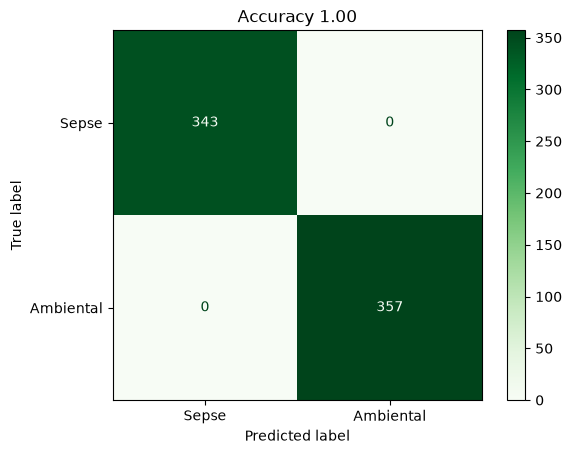


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00       343
       Sepse       1.00      1.00      1.00       357

    accuracy                           1.00       700
   macro avg       1.00      1.00      1.00       700
weighted avg       1.00      1.00      1.00       700

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [13]:
classificador = Classifier(df=df_train)

metricas_knn, pred_knn = classificador.classify(modelo="knn")

Support Vector Machine (SVM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel': 'rbf', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9971

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



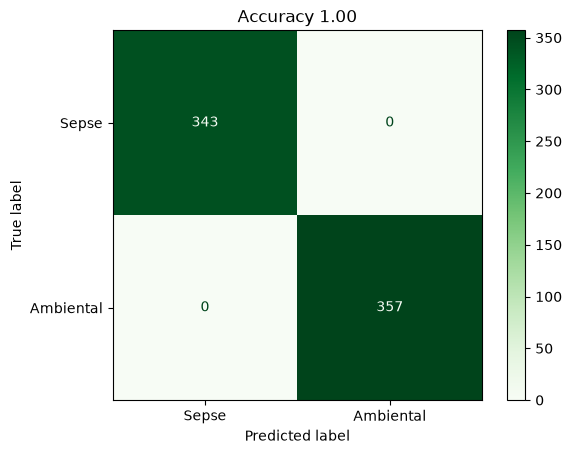


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00       343
       Sepse       1.00      1.00      1.00       357

    accuracy                           1.00       700
   macro avg       1.00      1.00      1.00       700
weighted avg       1.00      1.00      1.00       700

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [14]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

Random Forest (RF)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'gini', 'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 200, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9986

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



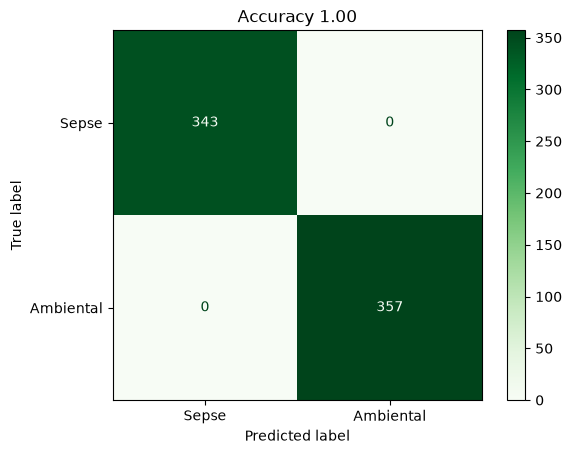


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00       343
       Sepse       1.00      1.00      1.00       357

    accuracy                           1.00       700
   macro avg       1.00      1.00      1.00       700
weighted avg       1.00      1.00      1.00       700

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [15]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

Gradient Boosting Machine (GBM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.1, 'gb__max_depth': 5, 'gb__n_estimators': 150, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9986

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



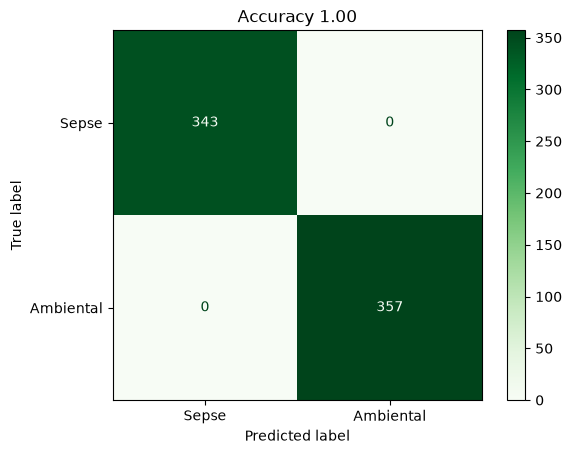


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00       343
       Sepse       1.00      1.00      1.00       357

    accuracy                           1.00       700
   macro avg       1.00      1.00      1.00       700
weighted avg       1.00      1.00      1.00       700

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [16]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

Naive Bayes (NB)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.001), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9900

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9929



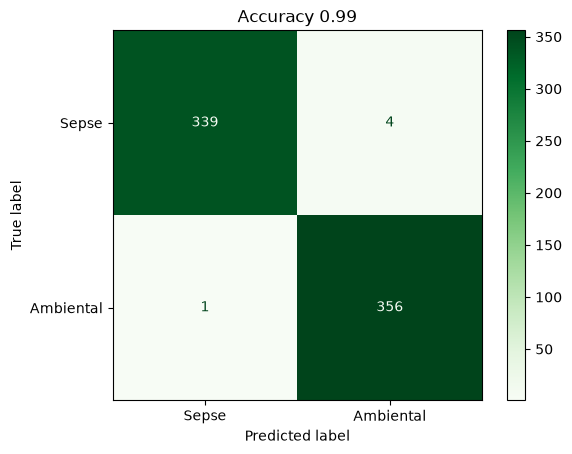


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      0.99      0.99       343
       Sepse       0.99      1.00      0.99       357

    accuracy                           0.99       700
   macro avg       0.99      0.99      0.99       700
weighted avg       0.99      0.99      0.99       700

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [17]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

Neural Network (NN)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (20, 10), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9957

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9986



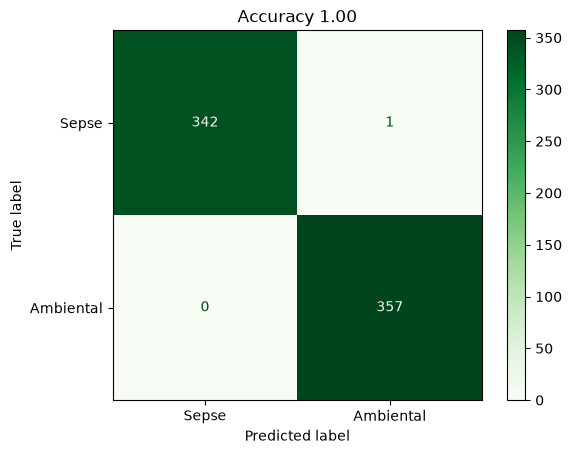


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00       343
       Sepse       1.00      1.00      1.00       357

    accuracy                           1.00       700
   macro avg       1.00      1.00      1.00       700
weighted avg       1.00      1.00      1.00       700

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [18]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

In [ ]:
#Organizando as métricas de treinamento
df_metricas_train = pd.concat(
    [
        metricas_knn.T,
        metricas_svm.T,
        metricas_rf.T,
        metricas_gbm.T,
        metricas_nb.T,
        metricas_nn.T,
    ]
)
df_metricas_train.reset_index(inplace=True)
df_metricas_train["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_train.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_train

,metricas,valores,modelo
0,Acurácia,1.0000,k-NN
1,Precision,1.0000,k-NN
2,Recall,1.0000,k-NN
3,F1-Score,1.0000,k-NN
4,Acurácia,1.0000,SVM
5,Precision,1.0000,SVM
6,Recall,1.0000,SVM
7,F1-Score,1.0000,SVM
8,Acurácia,1.0000,RF
9,Precision,1.0000,RF


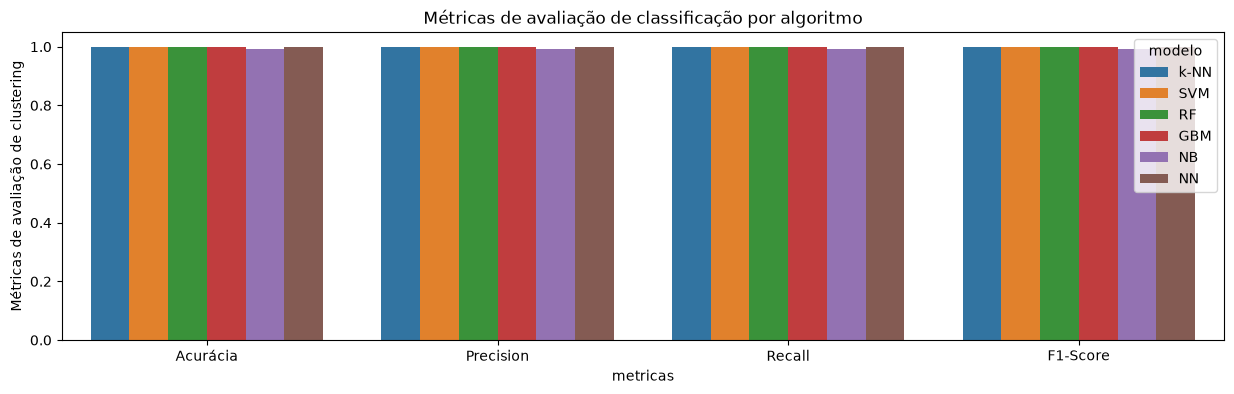

In [20]:
#Gráfico de barras das métricas
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train,
)
plt.ylabel("Métricas de avaliação de clustering")

plt.show()

In [ ]:
#Adicionando resultados de predição
df_train["k-NN"] = pred_knn.copy()
df_train["SVM"] = pred_svm.copy()
df_train["RF"] = pred_rf.copy()
df_train["GBM"] = pred_gbm.copy()
df_train["NB"] = pred_nb.copy()
df_train["NN"] = pred_nn.copy()
df_train.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,...,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,k-NN,SVM,RF,GBM,NB,NN
0,2,1,2,2,3,2,1,1,1,1,...,0,0,64.0,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse
1,2,1,2,2,2,2,2,1,1,1,...,0,0,32.0,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse
2,2,1,2,2,2,2,1,1,1,1,...,0,0,64.0,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse
3,2,0,0,2,2,2,1,1,0,1,...,0,0,4.0,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse
4,1,0,0,0,0,0,0,0,0,0,...,1,1,2.0,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental


# Validação

In [ ]:
#Concatenando tabelas de validação
df_valid = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_valid.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_valid.csv"),
    ],
    axis=1,
)

K-NN

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9950

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9950



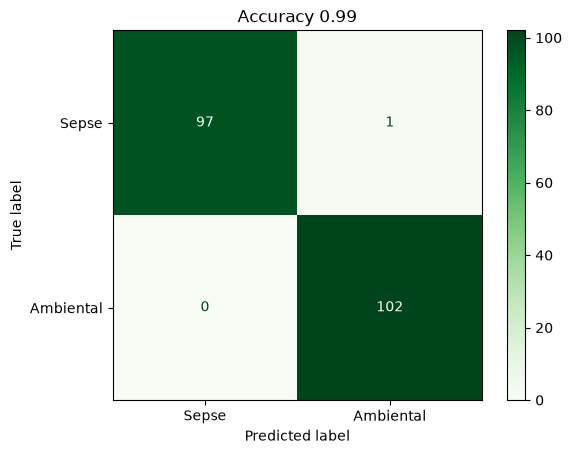


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      0.99      0.99        98
       Sepse       0.99      1.00      1.00       102

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [22]:
classificador = Classifier(df=df_valid)
metricas_knn, pred_knn = classificador.classify(modelo="knn")

SVM

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9950

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9950



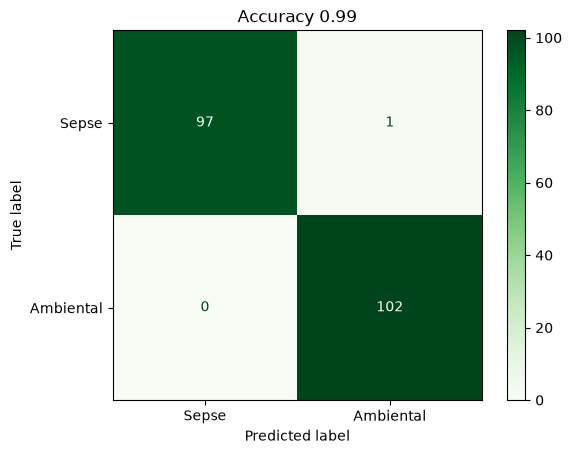


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      0.99      0.99        98
       Sepse       0.99      1.00      1.00       102

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [23]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

RF

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'gini', 'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 50, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9900

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



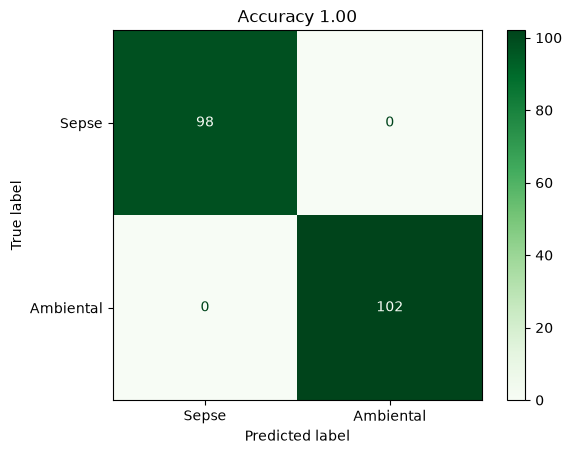


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00        98
       Sepse       1.00      1.00      1.00       102

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [24]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

GBM

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.1, 'gb__max_depth': 3, 'gb__n_estimators': 150, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9950

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



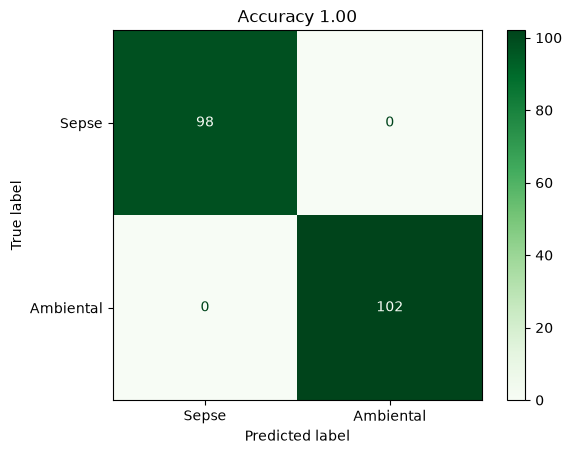


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00        98
       Sepse       1.00      1.00      1.00       102

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [25]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

NB

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.1), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9900

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9950



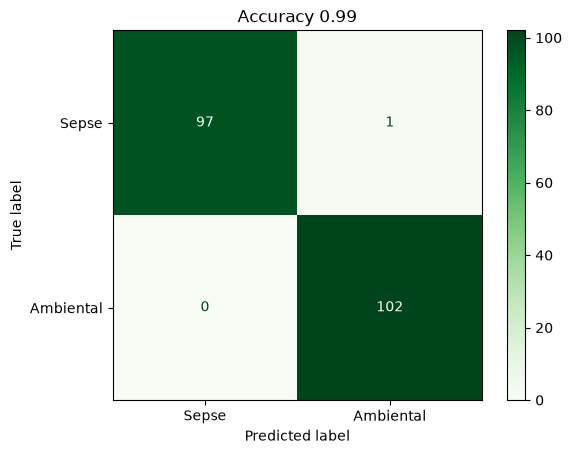


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      0.99      0.99        98
       Sepse       0.99      1.00      1.00       102

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [26]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

NN

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10,), 'mlp__solver': 'lbfgs', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9950

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



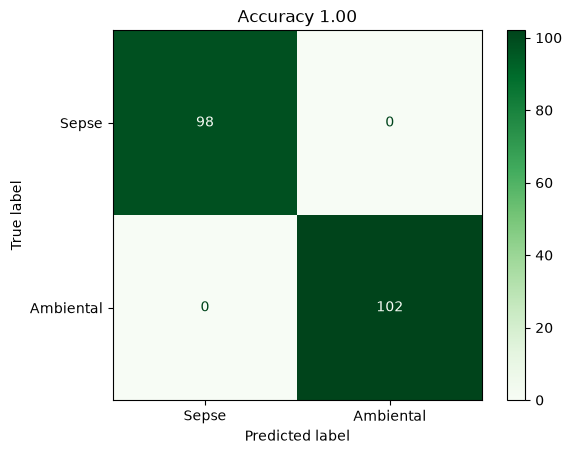


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00        98
       Sepse       1.00      1.00      1.00       102

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [27]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

In [28]:
#Organizando as métricas de treinamento
df_metricas_valid = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_valid.head()

,metricas,valores,modelo
0,Acurácia,0.995,k-NN
1,Precision,0.995,k-NN
2,Recall,0.995,k-NN
3,F1-Score,0.995,k-NN
4,Acurácia,0.995,SVM


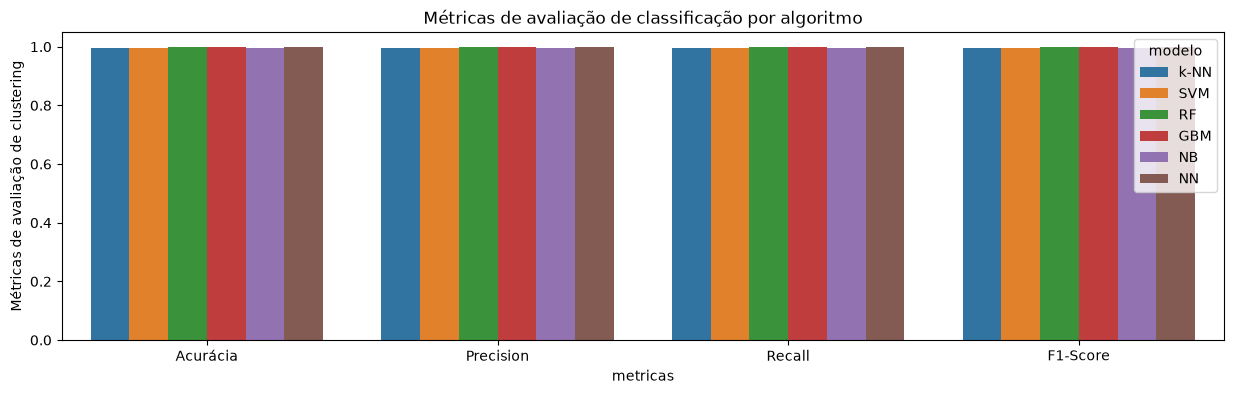

In [29]:
#Gráfico de barras das métricas
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid,
)
plt.ylabel("Métricas de avaliação de clustering")

plt.show()

In [30]:
#Adicionando grupos preditos
df_valid["k-NN"] = pred_knn.copy()
df_valid["SVM"] = pred_svm.copy()
df_valid["RF"] = pred_rf.copy()
df_valid["GBM"] = pred_gbm.copy()
df_valid["NB"] = pred_nb.copy()
df_valid["NN"] = pred_nn.copy()
df_valid.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,...,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,k-NN,SVM,RF,GBM,NB,NN
0,0,0,2,1,2,2,2,1,1,1,...,0,0,4.00,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse
1,1,0,1,0,3,1,2,1,0,1,...,1,1,2.00,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental
2,0,0,0,1,0,1,1,0,0,0,...,1,1,0.50,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental
3,1,1,2,0,0,0,0,0,1,0,...,2,1,8.00,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental
4,0,0,0,1,0,0,1,0,0,0,...,1,1,0.25,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental


# Teste

In [ ]:
#Concatenando tabelas de teste
df_test = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_test.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_test.csv"),
    ],
    axis=1,
)

K-NN

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 2, 'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9899

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9800



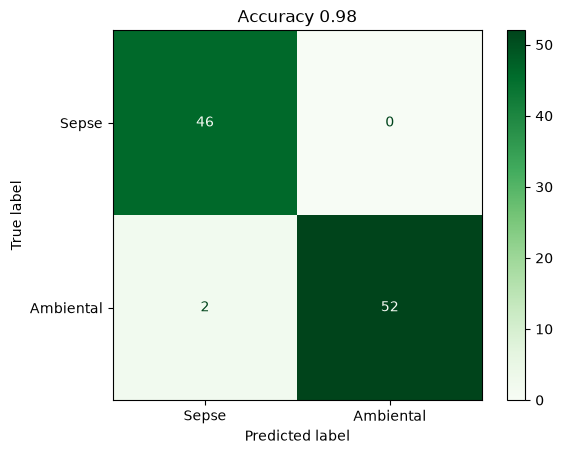


Classification Report:
              precision    recall  f1-score   support

   Ambiental       0.96      1.00      0.98        46
       Sepse       1.00      0.96      0.98        54

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_polimixinas
2. num__n_degradacao_aromaticos

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True              False
                  num__n_MBL              True              False
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos    

In [31]:
classificador = Classifier(df=df_test)
metricas_knn, pred_knn = classificador.classify(modelo="knn")

SVM

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 2, 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9899

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9800



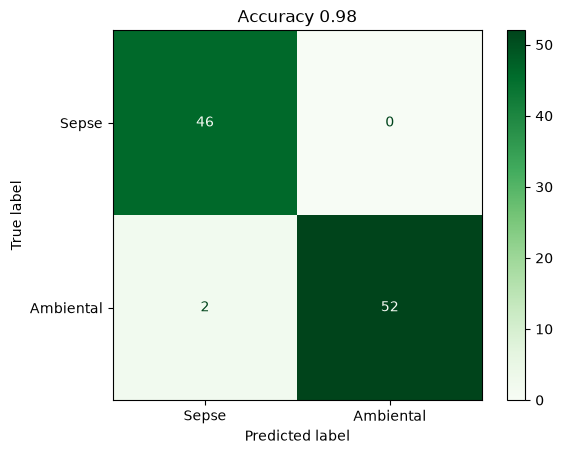


Classification Report:
              precision    recall  f1-score   support

   Ambiental       0.96      1.00      0.98        46
       Sepse       1.00      0.96      0.98        54

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_polimixinas
2. num__n_degradacao_aromaticos

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True              False
                  num__n_MBL              True              False
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos    

In [32]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

RF

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 2, 'rf__criterion': 'gini', 'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 50, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9899

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9800



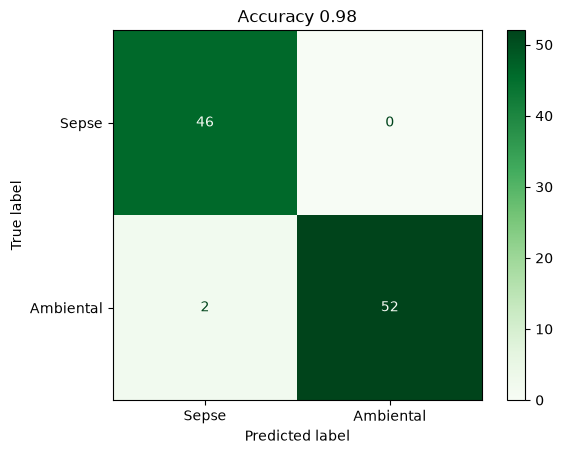


Classification Report:
              precision    recall  f1-score   support

   Ambiental       0.96      1.00      0.98        46
       Sepse       1.00      0.96      0.98        54

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_polimixinas
2. num__n_degradacao_aromaticos

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True              False
                  num__n_MBL              True              False
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos    

In [33]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

GBM

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 2, 'gb__learning_rate': 0.2, 'gb__max_depth': 3, 'gb__n_estimators': 50, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9899

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9800



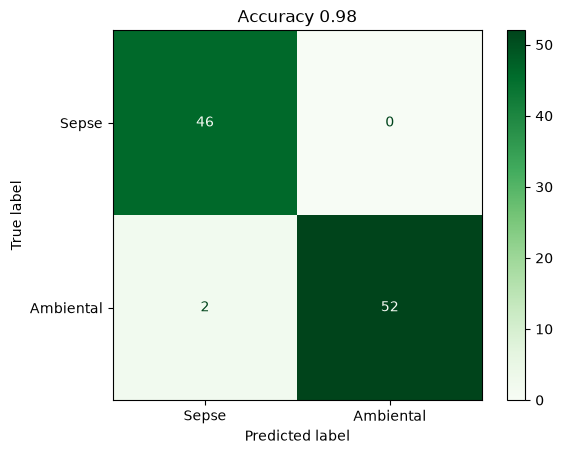


Classification Report:
              precision    recall  f1-score   support

   Ambiental       0.96      1.00      0.98        46
       Sepse       1.00      0.96      0.98        54

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_polimixinas
2. num__n_degradacao_aromaticos

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True              False
                  num__n_MBL              True              False
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos    

In [34]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

NB

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 2, 'nb__var_smoothing': np.float64(0.1), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.9899

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9800



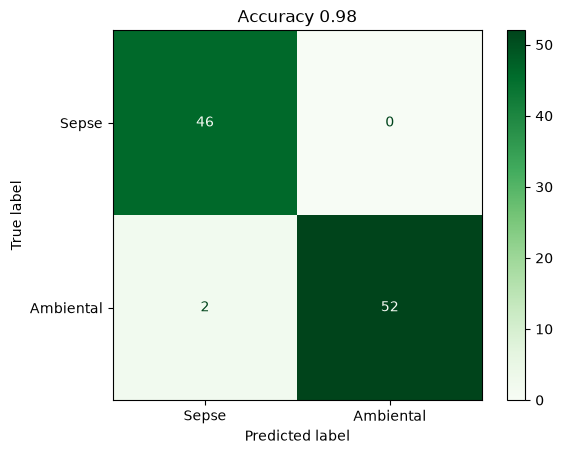


Classification Report:
              precision    recall  f1-score   support

   Ambiental       0.96      1.00      0.98        46
       Sepse       1.00      0.96      0.98        54

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__n_polimixinas
2. num__n_degradacao_aromaticos

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
                  num__n_OXA              True              False
                  num__n_MBL              True              False
               num__n_ISAba1              True              False
                 num__n_ESBL              True              False
     num__n_aminoglicosideos    

In [35]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

NN

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (20, 10), 'mlp__solver': 'lbfgs', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 1.0000

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



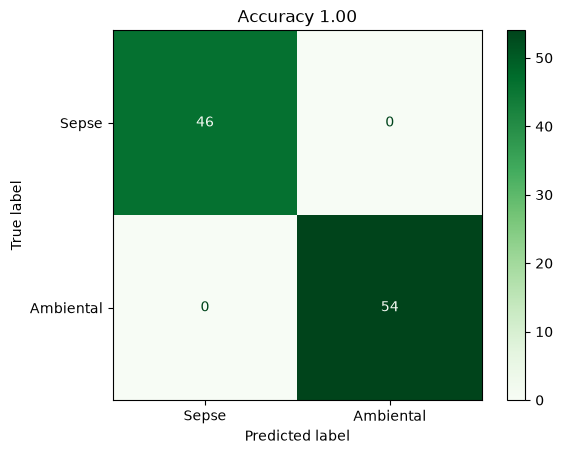


Classification Report:
              precision    recall  f1-score   support

   Ambiental       1.00      1.00      1.00        46
       Sepse       1.00      1.00      1.00        54

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__n_OXA
2. num__n_MBL
3. num__n_ISAba1
4. num__n_ESBL
5. num__n_aminoglicosideos
6. num__n_sulfa_trimetoprim
7. num__n_quinolonas
8. num__n_tetraciclina
9. num__n_efluxo_adeS
10. num__n_polimixinas
11. num__n_virulencia_clinica
12. num__n_ilha_AbaR
13. num__n_resistencia_metais
14. num__n_degradacao_aromaticos
15. num__MIC_imipenem

--- Status de Cada Atributo no Pipeline ---
      Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         

In [36]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

In [37]:
# Organizando as métricas de treinamento
df_metricas_test = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_test.reset_index(inplace=True)
df_metricas_test["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_test.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_test.head()

,metricas,valores,modelo
0,Acurácia,0.9800,k-NN
1,Precision,0.9808,k-NN
2,Recall,0.9800,k-NN
3,F1-Score,0.9800,k-NN
4,Acurácia,0.9800,SVM


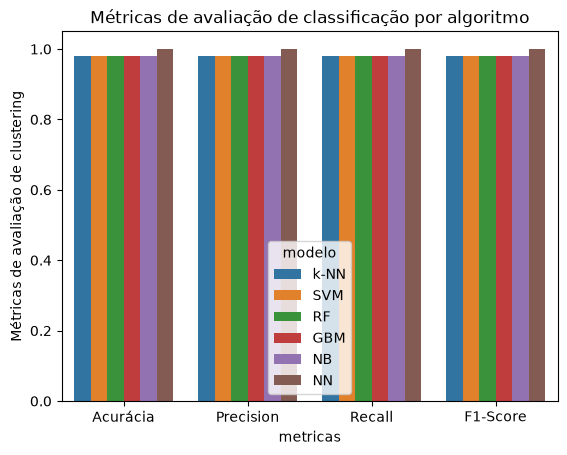

In [38]:
#Gráfico de barras das métricas
plt.title("Métricas de avaliação de classificação por algoritmo")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test,
)
plt.ylabel("Métricas de avaliação de clustering")

plt.show()

In [39]:
#Adicionando grupos preditos
df_test["k-NN"] = pred_knn.copy()
df_test["SVM"] = pred_svm.copy()
df_test["RF"] = pred_rf.copy()
df_test["GBM"] = pred_gbm.copy()
df_test["NB"] = pred_nb.copy()
df_test["NN"] = pred_nn.copy()
df_test.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,...,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo,k-NN,SVM,RF,GBM,NB,NN
0,0,0,1,1,0,0,0,0,1,0,...,2,1,0.5,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental
1,1,0,0,2,1,1,2,1,1,1,...,0,0,4.0,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse
2,2,1,2,2,3,2,2,1,1,1,...,0,1,32.0,Sepse,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Sepse
3,0,0,1,1,0,0,0,0,0,0,...,2,1,2.0,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental,Ambiental
4,1,1,0,1,3,2,2,1,1,1,...,0,0,4.0,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse,Sepse


In [46]:
#Salvando dataframes de resultado
pasta = Path("./modelo_class")
pasta.mkdir(parents=True, exist_ok=True)

dump(df_train, pasta / "classified_Treino")
dump(df_valid, pasta / "classified_Validacao")
dump(df_test, pasta / "classified_Teste")

['modelo_class/classified_Teste']

# Teste de hipótese

In [48]:
def testar_hipotese(df: pd.DataFrame) -> None:
    """
    Testa a hipótese de que a distribuição das classes no treino e no teste é estatisticamente igual (homogênea)
    ou diferente (heterogênea) usando o teste Qui-Quadrado.

    Parâmetros:
        df : pd.DataFrame
            DataFrame contendo as colunas 'Dataset' e 'Classe_Predita'.
        modelo : str
            Nome do modelo para exibição nos resultados.
    Retorna:
        None
    """
    # 3. Criando a Tabela de Contingência (Frequências Observadas)
    tabela_contingencia = pd.crosstab(df["Dataset"], df["Classe_Predita"])
    print("Tabela de Contingência (Observada):")
    print(tabela_contingencia)
    print("-" * 40)

    # 4. Realizando o Teste Qui-Quadrado
    chi2, p_valor, graus_liberdade, frequencias_esperadas = chi2_contingency(
        tabela_contingencia
    )

    # 5. Exibindo os resultados
    print(f"Estatística Qui-Quadrado: {chi2:.4f}")
    print(f"Graus de Liberdade: {graus_liberdade}")
    print(f"Valor-p: {p_valor:.4f}")

    # 6. Tomada de Decisão (usando nível de significância de 5%)
    alpha = 0.05
    print("\nConclusão:")
    if p_valor < alpha:
        print(
            "Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea)."
        )
    else:
        print(
            "Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea)."
        )

    return None

K-NN

In [49]:
modelo = "k-NN"
link = f"./modelo_class/classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_knn = load(link)
print(modelo)
display(df_knn.value_counts())
testar_hipotese(df_knn)

k-NN


Dataset  Classe_Predita
Treino   Sepse             357
         Ambiental         343
Teste    Sepse              52
         Ambiental          48
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  Ambiental  Sepse
Dataset                         
Teste                  48     52
Treino                343    357
----------------------------------------
Estatística Qui-Quadrado: 0.0064
Graus de Liberdade: 1
Valor-p: 0.9361

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


SVM

In [50]:
modelo = "SVM"
link = f"./modelo_class/classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_svm = load(link)
print(modelo)
display(df_svm.value_counts())
testar_hipotese(df_svm)

SVM


Dataset  Classe_Predita
Treino   Sepse             357
         Ambiental         343
Teste    Sepse              52
         Ambiental          48
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  Ambiental  Sepse
Dataset                         
Teste                  48     52
Treino                343    357
----------------------------------------
Estatística Qui-Quadrado: 0.0064
Graus de Liberdade: 1
Valor-p: 0.9361

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


RF

In [51]:
modelo = "RF"
link = f"./modelo_class/classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_rf = load(link)
print(modelo)
display(df_rf.value_counts())
testar_hipotese(df_rf)

RF


Dataset  Classe_Predita
Treino   Sepse             357
         Ambiental         343
Teste    Sepse              52
         Ambiental          48
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  Ambiental  Sepse
Dataset                         
Teste                  48     52
Treino                343    357
----------------------------------------
Estatística Qui-Quadrado: 0.0064
Graus de Liberdade: 1
Valor-p: 0.9361

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


GBM

In [52]:
modelo = "GBM"
link = f"./modelo_class/classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_gbm = load(link)
print(modelo)
display(df_gbm.value_counts())
testar_hipotese(df_gbm)

GBM


Dataset  Classe_Predita
Treino   Sepse             357
         Ambiental         343
Teste    Sepse              52
         Ambiental          48
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  Ambiental  Sepse
Dataset                         
Teste                  48     52
Treino                343    357
----------------------------------------
Estatística Qui-Quadrado: 0.0064
Graus de Liberdade: 1
Valor-p: 0.9361

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


NB

In [53]:
modelo = "NB"
link = f"./modelo_class/classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_nb = load(link)
print(modelo)
display(df_nb.value_counts())
testar_hipotese(df_nb)

NB


Dataset  Classe_Predita
Treino   Sepse             360
         Ambiental         340
Teste    Sepse              52
         Ambiental          48
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  Ambiental  Sepse
Dataset                         
Teste                  48     52
Treino                340    360
----------------------------------------
Estatística Qui-Quadrado: 0.0000
Graus de Liberdade: 1
Valor-p: 1.0000

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


NN

In [54]:
modelo = "NN"
link = f"./modelo_class/classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_nn = load(link)
print(modelo)
display(df_nn.value_counts())
testar_hipotese(df_nn)

NN


Dataset  Classe_Predita
Treino   Sepse             358
         Ambiental         342
Teste    Sepse              54
         Ambiental          46
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  Ambiental  Sepse
Dataset                         
Teste                  46     54
Treino                342    358
----------------------------------------
Estatística Qui-Quadrado: 0.1830
Graus de Liberdade: 1
Valor-p: 0.6688

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).
